# HL2027 Project 1 – Radial sampling in MRI

## Goal of the project
MRI scans take a long time, because the scanner has to measure a lot of data in k-space (the Fourier domain of the image).
With normal Cartesian sampling, k-space is measured line by line, and we need all lines to follow the Nyquist theorem.
If we measure less data, the scan is faster, but the image gets artifacts or noise.

Radial sampling is one way to measure less data. Instead of lines, we measure "spokes": straight lines through the centre of k-space
at different angles. In this project we want to find out *how few spokes we can measure* and still get a good image,
and *which reconstruction method* works best.

### Plan:
1. *Simulate* radial sampling: we take a real T1-weighted brain image as ground truth and compute the k-space values that a radial scan would measure (Task 1).
2. *Define quality measures* (PSNR, SSIM, difference maps) to compare every reconstruction with the ground truth (Task 2).
3. *Reconstruct* the image from the radial data with different methods:
   - gridding / NUFFT with density compensation (Task 3),
   - compressed sensing with L1-wavelet and total variation (Task 4),
   - CT methods: build a sinogram directly from the radial data and use filtered back projection (Tasks 5 and 6).
4. *Compare* the methods for acceleration factors up to R = 10.
5. Apply the *best method to the whole 3D volume* for R = 5 and R = 10 (Task 7).

**Files:** `t1.nii`, `projection_ksp.npy` and `projection_coord.npy` must be in the same folder as this notebook :)

In [1]:
# %pip install sigpy scikit-image matplotlib SimpleITK # -> Installed needed packages once 

In [2]:
# Libraries:
import numpy as np
import SimpleITK as sitk
import sigpy as sp
import sigpy.mri as mr
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110  

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
## Task 1 – Simulation of radial sampling

**Aim of Task 1:**
We want to simulate a radial MRI scan. We start from the finished image,
compute which k-space values a radial scanner would measure, and work out how much faster this is than Cartesian sampling.
All later tasks use this simulated data as their input.

---
### 1.1 Load the data
- The file holds a 3D volume with 90 slices of 256 × 256 pixels.
- For Tasks 1–6 we use only one slice, the middle one (number 45).
- We scale the values to the range 0 to 1. Then the value range for PSNR/SSIM in Task 2 is clear (`data_range=1`).

Volume: (90, 256, 256) int16 | value range 0 - 740


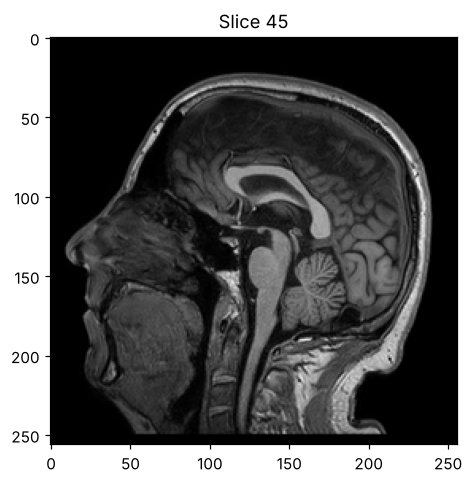

In [3]:
# Read the volume
sitk_t1 = sitk.ReadImage('t1.nii')         
t1 = sitk.GetArrayFromImage(sitk_t1)        # ->  NumPy array, axis order (z, y, x) = (slices, rows, columns)
print('Volume:', t1.shape, t1.dtype, '| value range', t1.min(), '-', t1.max())

# Only one slice
img = t1[45].astype(np.float64)             # slice 45 as decimal numbers (int can cause problems in calculations)
img = img / img.max()                       # scale: brightest pixel = 1, background = 0
N = img.shape[0]                            # image size in one direction: 256

plt.imshow(img, cmap='gray')
plt.title('Slice 45')
plt.axis('on');

---
### 1.2 Radial coordinates
We want to find out where in k-space a radial scanner measures.
We create the coordinates of all spokes with sigpy, spread evenly over the full circle (no golden angle).
These coordinates tell us later which k-space values we take from the image in Task 1.3.

---

`mr.radial(coord_shape, img_shape, golden=False)` returns an array with shape **(spokes, 256, 2)**:
- 1st axis: which spoke
- 2nd axis: which sample on the spoke (256 samples)
- 3rd axis: the two coordinates (ky, kx) of this sample in k-space

The unit is "grid points": the k-space of a 256 × 256 image goes from −128 to +128. The centre (0, 0) holds the overall brightness of the image.

*Why `golden=False`?* With the golden angle, each new spoke is turned by about 111.25°. This is useful for dynamic MRI, but for a fixed number of spokes the spokes are not spread perfectly evenly. 

In [4]:
def radial_coords(spokes, n_ro=256, img_shape=(256, 256)):
    """k-space coordinates for radial sampling with evenly spread spokes.

    spokes    : number of spokes (lines)
    n_ro      : samples per spoke, 256 in this task
    img_shape : image size, sets how far k-space goes
    returns   : array (spokes, n_ro, 2) with (ky, kx) of every sample
    """
    return mr.radial([spokes, n_ro, 2], list(img_shape), golden=False)

---
### 1.3 Simulate the measurement (k-space at the radial points)
We want to simulate what a radial scanner would measure.
For this, we compute the k-space values of our image exactly at the radial coordinates from Task 1.2, using the non-uniform Fourier transform (NUFFT).
The result is our simulated raw data, which we use as input for all reconstructions in the next tasks.

---

**Problem:** The FFT only gives values on the integer grid (…, −1, 0, 1, 2, …).
Most radial points lie between these grid points.

**Solution:** the *non-uniform Fourier transform (NUFFT)*, in sigpy `sp.nufft(image, coordinates)`

It computes the Fourier transform directly at any points. Inside, it does an FFT on a finer grid
and then interpolates to the wanted points with a Kaiser-Bessel kernel.

The result is an array **(spokes, 256)**: one complex value per coordinate. This is our simulated raw data.

In [5]:
def simulate_radial_ksp(img, coord):
    """Simulates a radial MRI measurement of the image.

    img   : 2D image (ground truth)
    coord : radial coordinates from radial_coords(), shape (spokes, 256, 2)
    returns: complex k-space values, shape (spokes, 256)
    """
    # NUFFT needs complex numbers as input, so we convert the image
    return sp.nufft(img.astype(np.complex64), coord)


# Example: simulate a radial scan with 64 spokes (R = 4)
ksp = simulate_radial_ksp(img, radial_coords(64))
print('k-space data:', ksp.shape, '-> (spokes, samples per spoke)')
print('Data type:', ksp.dtype, '(complex: magnitude and phase)')

k-space data: (64, 256) -> (spokes, samples per spoke)
Data type: complex64 (complex: magnitude and phase)


---
### 1.4 Acceleration factor R

We want to know how much faster radial sampling is compared to full Cartesian sampling.
For this, we compare the number of measured values and compute the acceleration factor R = 256 / spokes.

---

The scan time is roughly proportional to the number of measured values. So we compare the numbers:

- **Cartesian (fully sampled):** 256 lines × 256 samples = 65 536 values
- **Radial:** spokes × 256 samples

$$R = \frac{256 \cdot 256}{\text{spokes} \cdot 256} = \frac{256}{\text{spokes}}$$

So for R = 10 we only need about 26 spokes. 

In [6]:
def acceleration(spokes, n_ro=256, img_shape=(256, 256)):
    """Acceleration factor: Cartesian samples / radial samples."""
    return np.prod(img_shape) / (spokes * n_ro)


def spokes_for(R, n_ro=256, img_shape=(256, 256)):
    """The other way round: how many spokes for a wanted factor R? (rounded to whole spokes)"""
    return int(round(np.prod(img_shape) / (R * n_ro)))


R_values = list(range(1, 11))                       # R = 1, 2, ..., 10
spokes_list = [spokes_for(R) for R in R_values]     # we use this list again in Tasks 3 and 4

# Table for the report :)
print(' R  | spokes | exact R')
print('----+--------+--------')
for R, s in zip(R_values, spokes_list):
    print(f'{R:3d} | {s:6d} | {acceleration(s):6.2f}')   # "exact", because spokes must be whole numbers

print('\nNyquist would need about', int(np.ceil(2 * np.pi * N / 2)), 'half spokes')

 R  | spokes | exact R
----+--------+--------
  1 |    256 |   1.00
  2 |    128 |   2.00
  3 |     85 |   3.01
  4 |     64 |   4.00
  5 |     51 |   5.02
  6 |     43 |   5.95
  7 |     37 |   6.92
  8 |     32 |   8.00
  9 |     28 |   9.14
 10 |     26 |   9.85

Nyquist would need about 805 half spokes


---
### 1.5 Figure for the report

We want to show in one figure what radial sampling looks like and what information gets lost.
We plot the original image, its full Cartesian k-space and the radial sampling patterns for R ≈ 2 and R ≈ 10.

---
Four images side by side:
1. the original image,
2. its full Cartesian k-space (on a log scale, otherwise you only see the bright point in the centre),
3. the radial sample points for R ≈ 2, and
4. for R ≈ 10, where the outer k-space stays almost empty.

The outer part of k-space holds the fine details and edges of the image. 
The inner part holds the rough contrast.
So fewer spokes mainly means: details get lost or turn into streak artifacts.

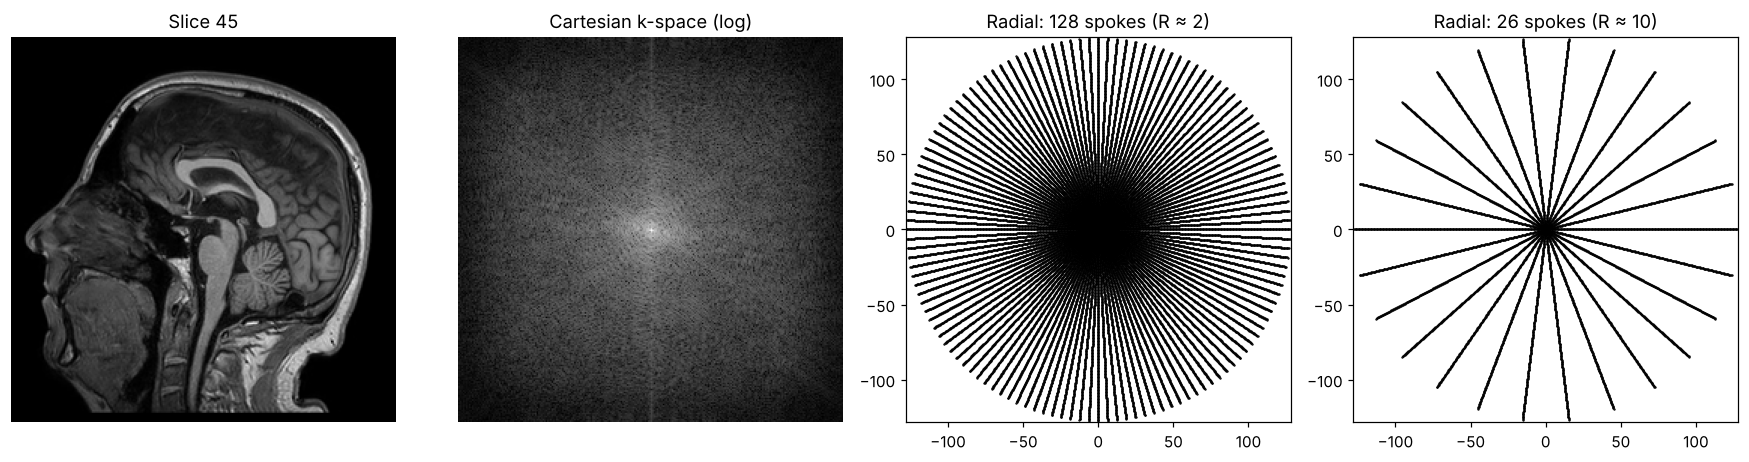

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

# (1) Original image
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Slice 45')

# (2) Cartesian k-space: centred 2D FFT
#     ifftshift before / fftshift after -> the centre of k-space is in the middle of the picture
kcart = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(img)))
ax[1].imshow(np.log1p(np.abs(kcart)), cmap='gray')   # log(1 + |k|), so that weak values are visible too
ax[1].set_title('Cartesian k-space (log)')

# (3) + (4) Radial trajectories for R ≈ 2 and R ≈ 10
for a, R in zip(ax[2:], [2, 10]):
    s = spokes_for(R)
    c = radial_coords(s)
    a.scatter(c[..., 1].ravel(), c[..., 0].ravel(), s=0.3, c='k')   # x = kx, y = ky; each dot = one measured value
    a.set_aspect('equal')
    a.set_xlim(-128, 128); a.set_ylim(-128, 128)
    a.set_title(f'Radial: {s} spokes (R ≈ {R})')

for a in ax[:2]:
    a.axis('off')

plt.tight_layout()
plt.savefig('task1_sampling.png', dpi=150, bbox_inches='tight') 
plt.show()

---
## Task 2 – Quality assessment (10 %)

### Goal of Task 2
We want tools to measure **how good a reconstruction is**. Because we have the original image (ground truth),
we can compare every reconstruction directly with it.
We build these tools once here and then use them in Tasks 3–7 for every method and every number of spokes.

### What does the task ask for?
1. **Qualitative assessment:** show the reconstructed image next to the original, and a **difference map** (original − reconstruction).
2. **Quantitative assessment:** compute at least **PSNR** and **SSIM** with scikit-image.
3. *Optional:* use more measures from scikit-image. We add **NRMSE**.

### 2.1 The quality measures

**Aim of Task 2.1:**
We want numbers that tell us how close a reconstruction is to the original image.

- **PSNR (peak signal-to-noise ratio)**, in decibel (dB).
  It looks at the pixel-wise error (mean squared error, MSE) compared to the brightest possible value:
  $$\text{PSNR} = 10 \cdot \log_{10}\left(\frac{\text{data\_range}^2}{\text{MSE}}\right)$$
  **Higher is better.** Rough guide: below 25 dB poor, above 30 dB good, above 35 dB very good.
- **SSIM (structural similarity index)**, between 0 and 1.
  It compares local **brightness, contrast and structure** in small windows, so it is closer to how a human sees the image.
  **1 means identical.**
- **NRMSE (normalized root mean squared error)**, optional.
  The pixel-wise error relative to the size of the original image. **Lower is better**, 0 means identical.

**Two things we must take care of before comparing:**
1. **Complex images:** reconstructions come out as complex numbers. We compare the **magnitude** (`np.abs`), like a normal MR image.
2. **Brightness scale:** a reconstruction can be brighter or darker overall than the original (for example because of density compensation in Task 3).
   This would make PSNR worse even if the image looks good. So we first **scale the reconstruction** with one factor that fits it best to the original
   (least squares fit). This changes only the overall brightness, not the structure, so the comparison stays fair.

In [8]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity, normalized_root_mse


def prepare(recon, reference):
    """Make a reconstruction ready for comparison with the reference image.

    1. take the magnitude (reconstructions can be complex)
    2. scale it with one factor so that its brightness fits the reference best
       (least squares: the factor a that makes |reference - a * recon|^2 smallest)
    """
    recon = np.abs(recon).astype(np.float64)
    a = np.sum(reference * recon) / np.sum(recon * recon)   # best scale factor
    return a * recon


def quality(reference, recon):
    """Compute PSNR, SSIM and NRMSE between the reference (ground truth) and a reconstruction.

    reference : original image, values in [0, 1]
    recon     : reconstructed image (can be complex and have a different scale)
    returns   : dict with the three measures
    """
    recon = prepare(recon, reference)
    with np.errstate(divide='ignore'):          # identical images give MSE = 0 -> PSNR = inf; hide the warning
        psnr = peak_signal_noise_ratio(reference, recon, data_range=1.0)   # data_range = 1 because the reference is in [0, 1]
    return {
        'PSNR': psnr,
        'SSIM': structural_similarity(reference, recon, data_range=1.0),
        'NRMSE': normalized_root_mse(reference, recon),
    }

### 2.2 Difference map and comparison figure

**Aim of Task 2.2:**
We want to see **where** the errors are, not only how big they are.
The difference map is original − reconstruction. White (zero) means no error. Red and blue patterns show where the reconstruction is wrong (red: too dark, blue: too bright),
for example the typical streak artifacts of radial sampling.

We use one shared colour scale for the difference map (from −max to +max), so that maps of different methods can be compared fairly.

In [9]:
def show_comparison(reference, recon, title='Reconstruction', diff_range=0.3, save_as=None):
    """Show original, reconstruction and difference map side by side, with the quality measures in the title.

    reference  : original image
    recon      : reconstructed image (can be complex / differently scaled)
    title      : name of the method, shown above the reconstruction
    diff_range : colour scale of the difference map goes from -diff_range to +diff_range
                 (keep it the same for all figures, so they can be compared)
    save_as    : file name to save the figure (optional)
    """
    recon_p = prepare(recon, reference)          # magnitude + scaled, same as used for the numbers
    q = quality(reference, recon)
    diff = reference - recon_p                   # difference map: original - reconstruction

    fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))

    ax[0].imshow(reference, cmap='gray', vmin=0, vmax=1)
    ax[0].set_title('Original (ground truth)')

    ax[1].imshow(recon_p, cmap='gray', vmin=0, vmax=1)
    ax[1].set_title(f'{title}\nPSNR {q["PSNR"]:.2f} dB | SSIM {q["SSIM"]:.3f}')

    im = ax[2].imshow(diff, cmap='seismic', vmin=-diff_range, vmax=diff_range)   # blue = too bright, red = too dark
    ax[2].set_title(f'Difference (original − recon)\nNRMSE {q["NRMSE"]:.3f}')
    fig.colorbar(im, ax=ax[2], fraction=0.046)

    for a in ax:
        a.axis('off')
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches='tight')
    plt.show()
    return q

### 2.3 Test the tools

**Aim of Task 2.3:**
We want to check that our measures behave as expected **before** we use them on real reconstructions.
We do not have a reconstruction yet (this comes in Task 3), so we use three simple test cases:

1. the original compared with **itself** → must give the best values (PSNR = ∞, SSIM = 1, NRMSE = 0),
2. the original with **random noise** added → errors everywhere,
3. a **blurred** version of the original → loses fine details, similar to missing the outer k-space.

We also check that the scaling works: a darker copy of the image (half the brightness) must still count as perfect.

In [10]:
from scipy.ndimage import gaussian_filter

rng = np.random.default_rng(0)                          # fixed seed -> same noise every time

tests = {
    'identical':        img.copy(),
    'half brightness':  0.5 * img,                      # same structure, only darker -> scaling must fix this
    'noise (σ = 0.05)': img + rng.normal(0, 0.05, img.shape),
    'blur (σ = 1.5 px)': gaussian_filter(img, sigma=1.5),
}

print(f'{"test case":20s} | {"PSNR [dB]":>9s} | {"SSIM":>6s} | {"NRMSE":>6s}')
print('-' * 50)
for name, test_img in tests.items():
    q = quality(img, test_img)
    print(f'{name:20s} | {q["PSNR"]:9.2f} | {q["SSIM"]:6.3f} | {q["NRMSE"]:6.3f}')
# Expected: identical and half brightness are perfect (PSNR = inf, SSIM = 1),
#           noise and blur are clearly worse.

test case            | PSNR [dB] |   SSIM |  NRMSE
--------------------------------------------------
identical            |       inf |  1.000 |  0.000
half brightness      |       inf |  1.000 |  0.000
noise (σ = 0.05)     |     26.38 |  0.561 |  0.199
blur (σ = 1.5 px)    |     26.06 |  0.818 |  0.206


The table shows why we need **both** measures:
noise and blur can give a similar PSNR, but SSIM reacts differently, because blur destroys structure (edges) while noise mostly adds random errors.
Now we look at the difference maps of the two "bad" cases.

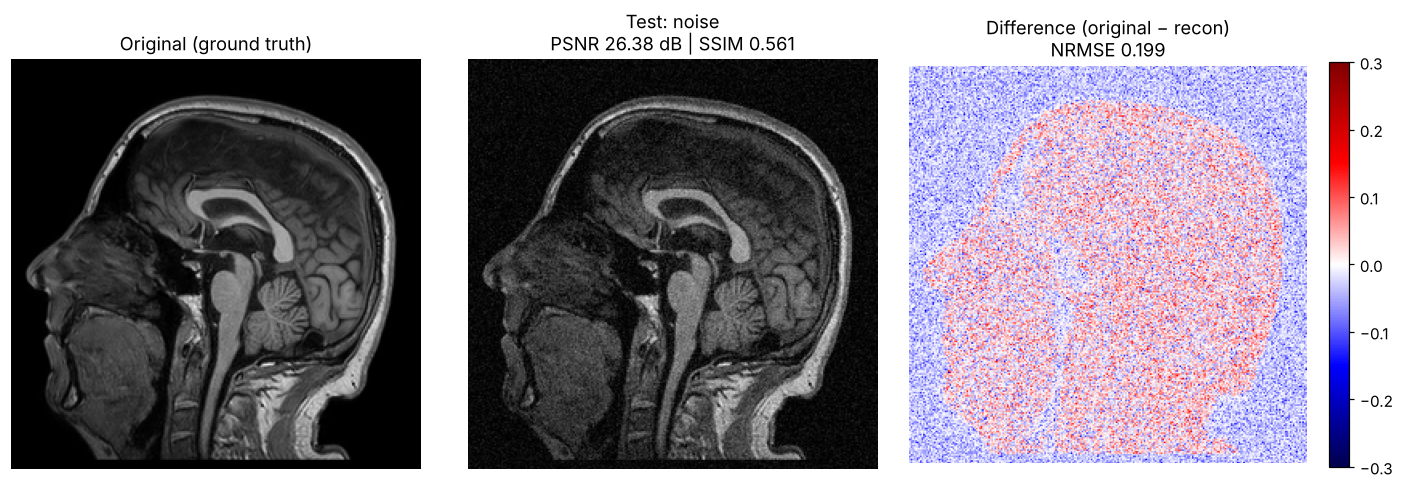

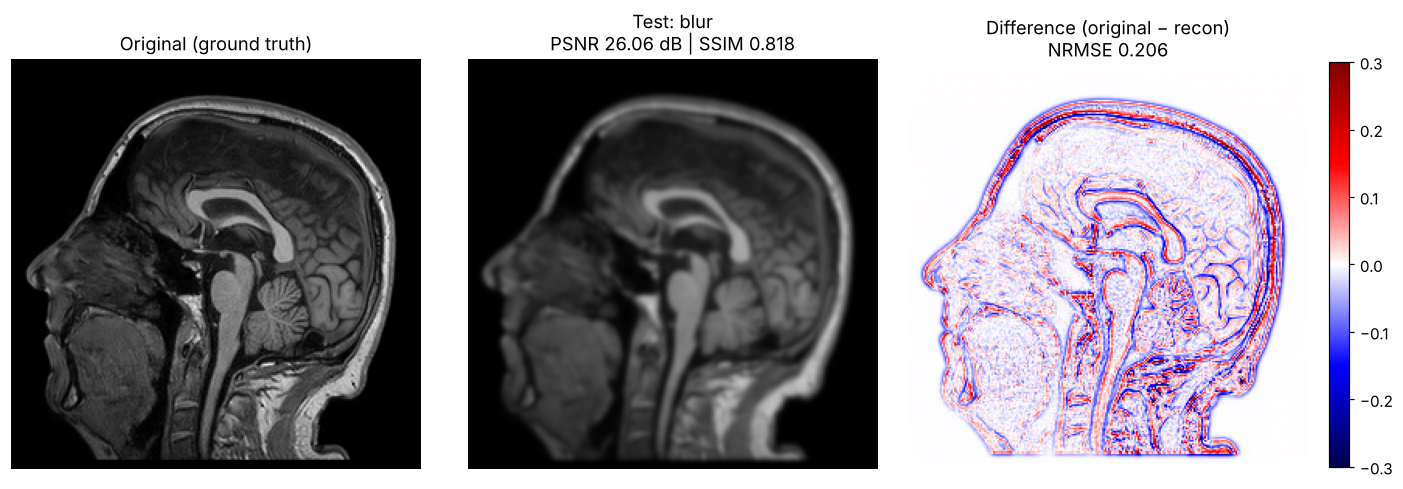

In [11]:
show_comparison(img, tests['noise (σ = 0.05)'], title='Test: noise')
show_comparison(img, tests['blur (σ = 1.5 px)'], title='Test: blur', save_as='task2_example.png');

**Summary of Task 2:** We now have `quality()` for the numbers and `show_comparison()` for the figures.
From Task 3 on, we call them for every reconstruction and every number of spokes, and plot PSNR and SSIM against the acceleration factor R.

---
## Task 3 – Reconstruction with the non-uniform Fourier transform (NUFFT)
*coming in the next step*